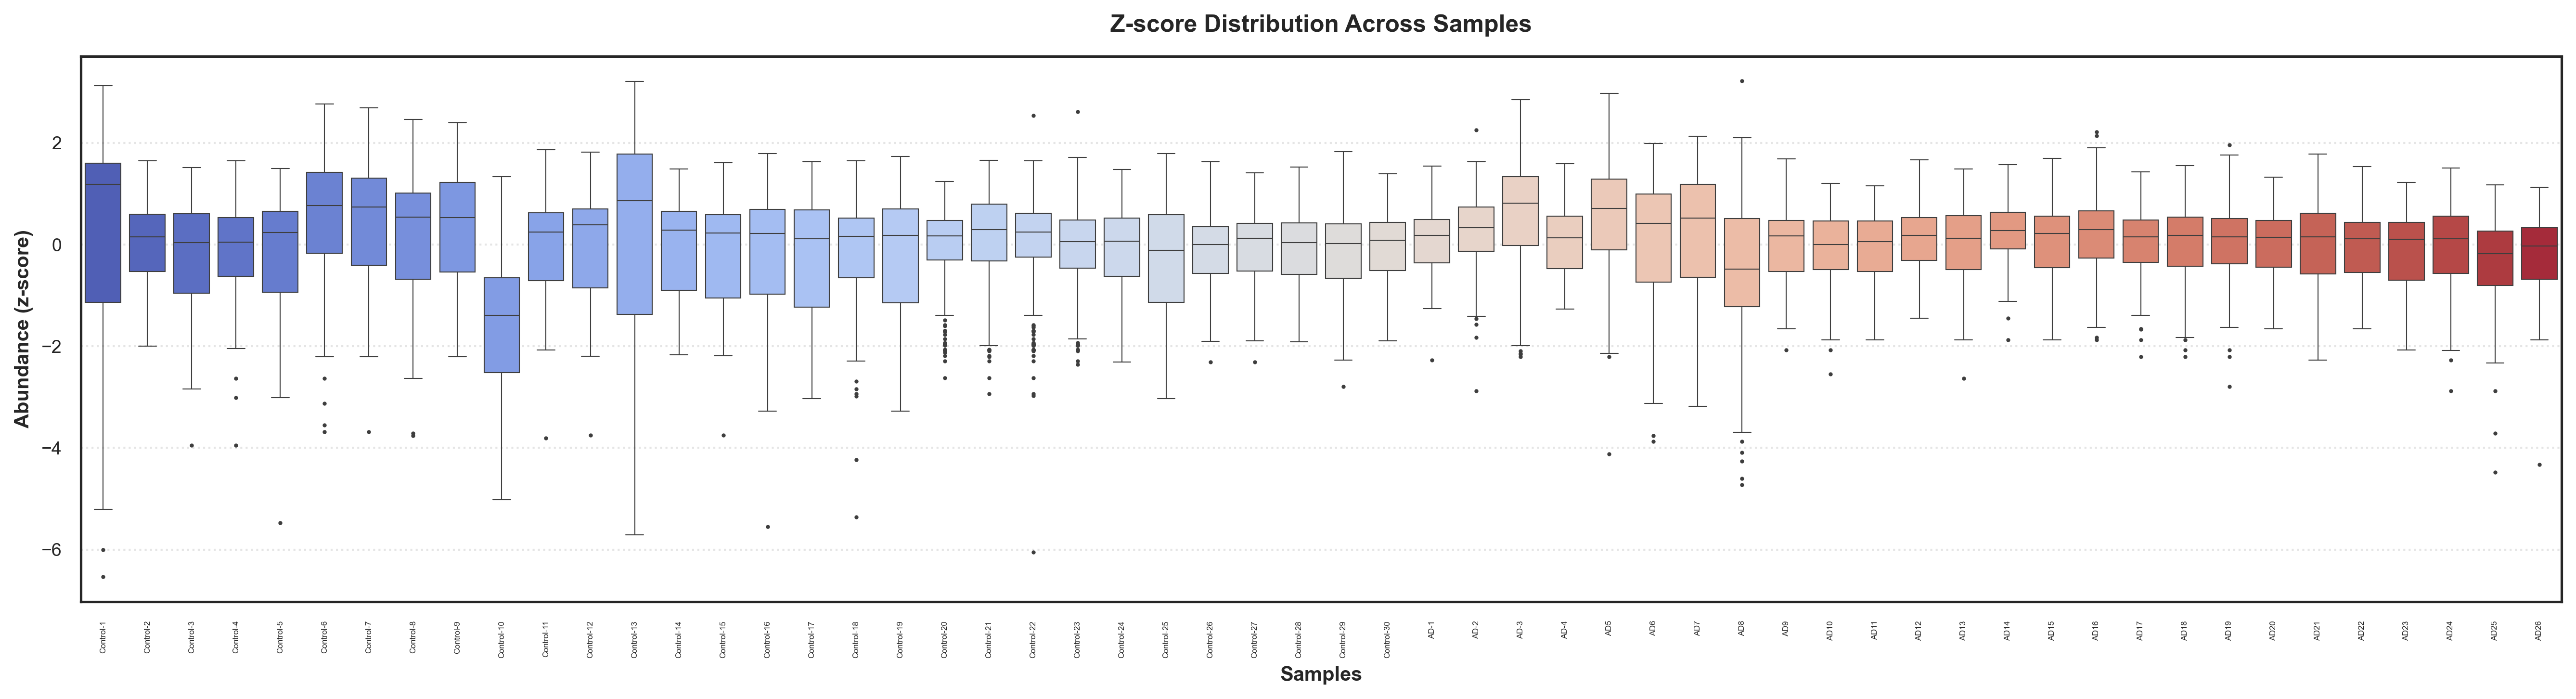

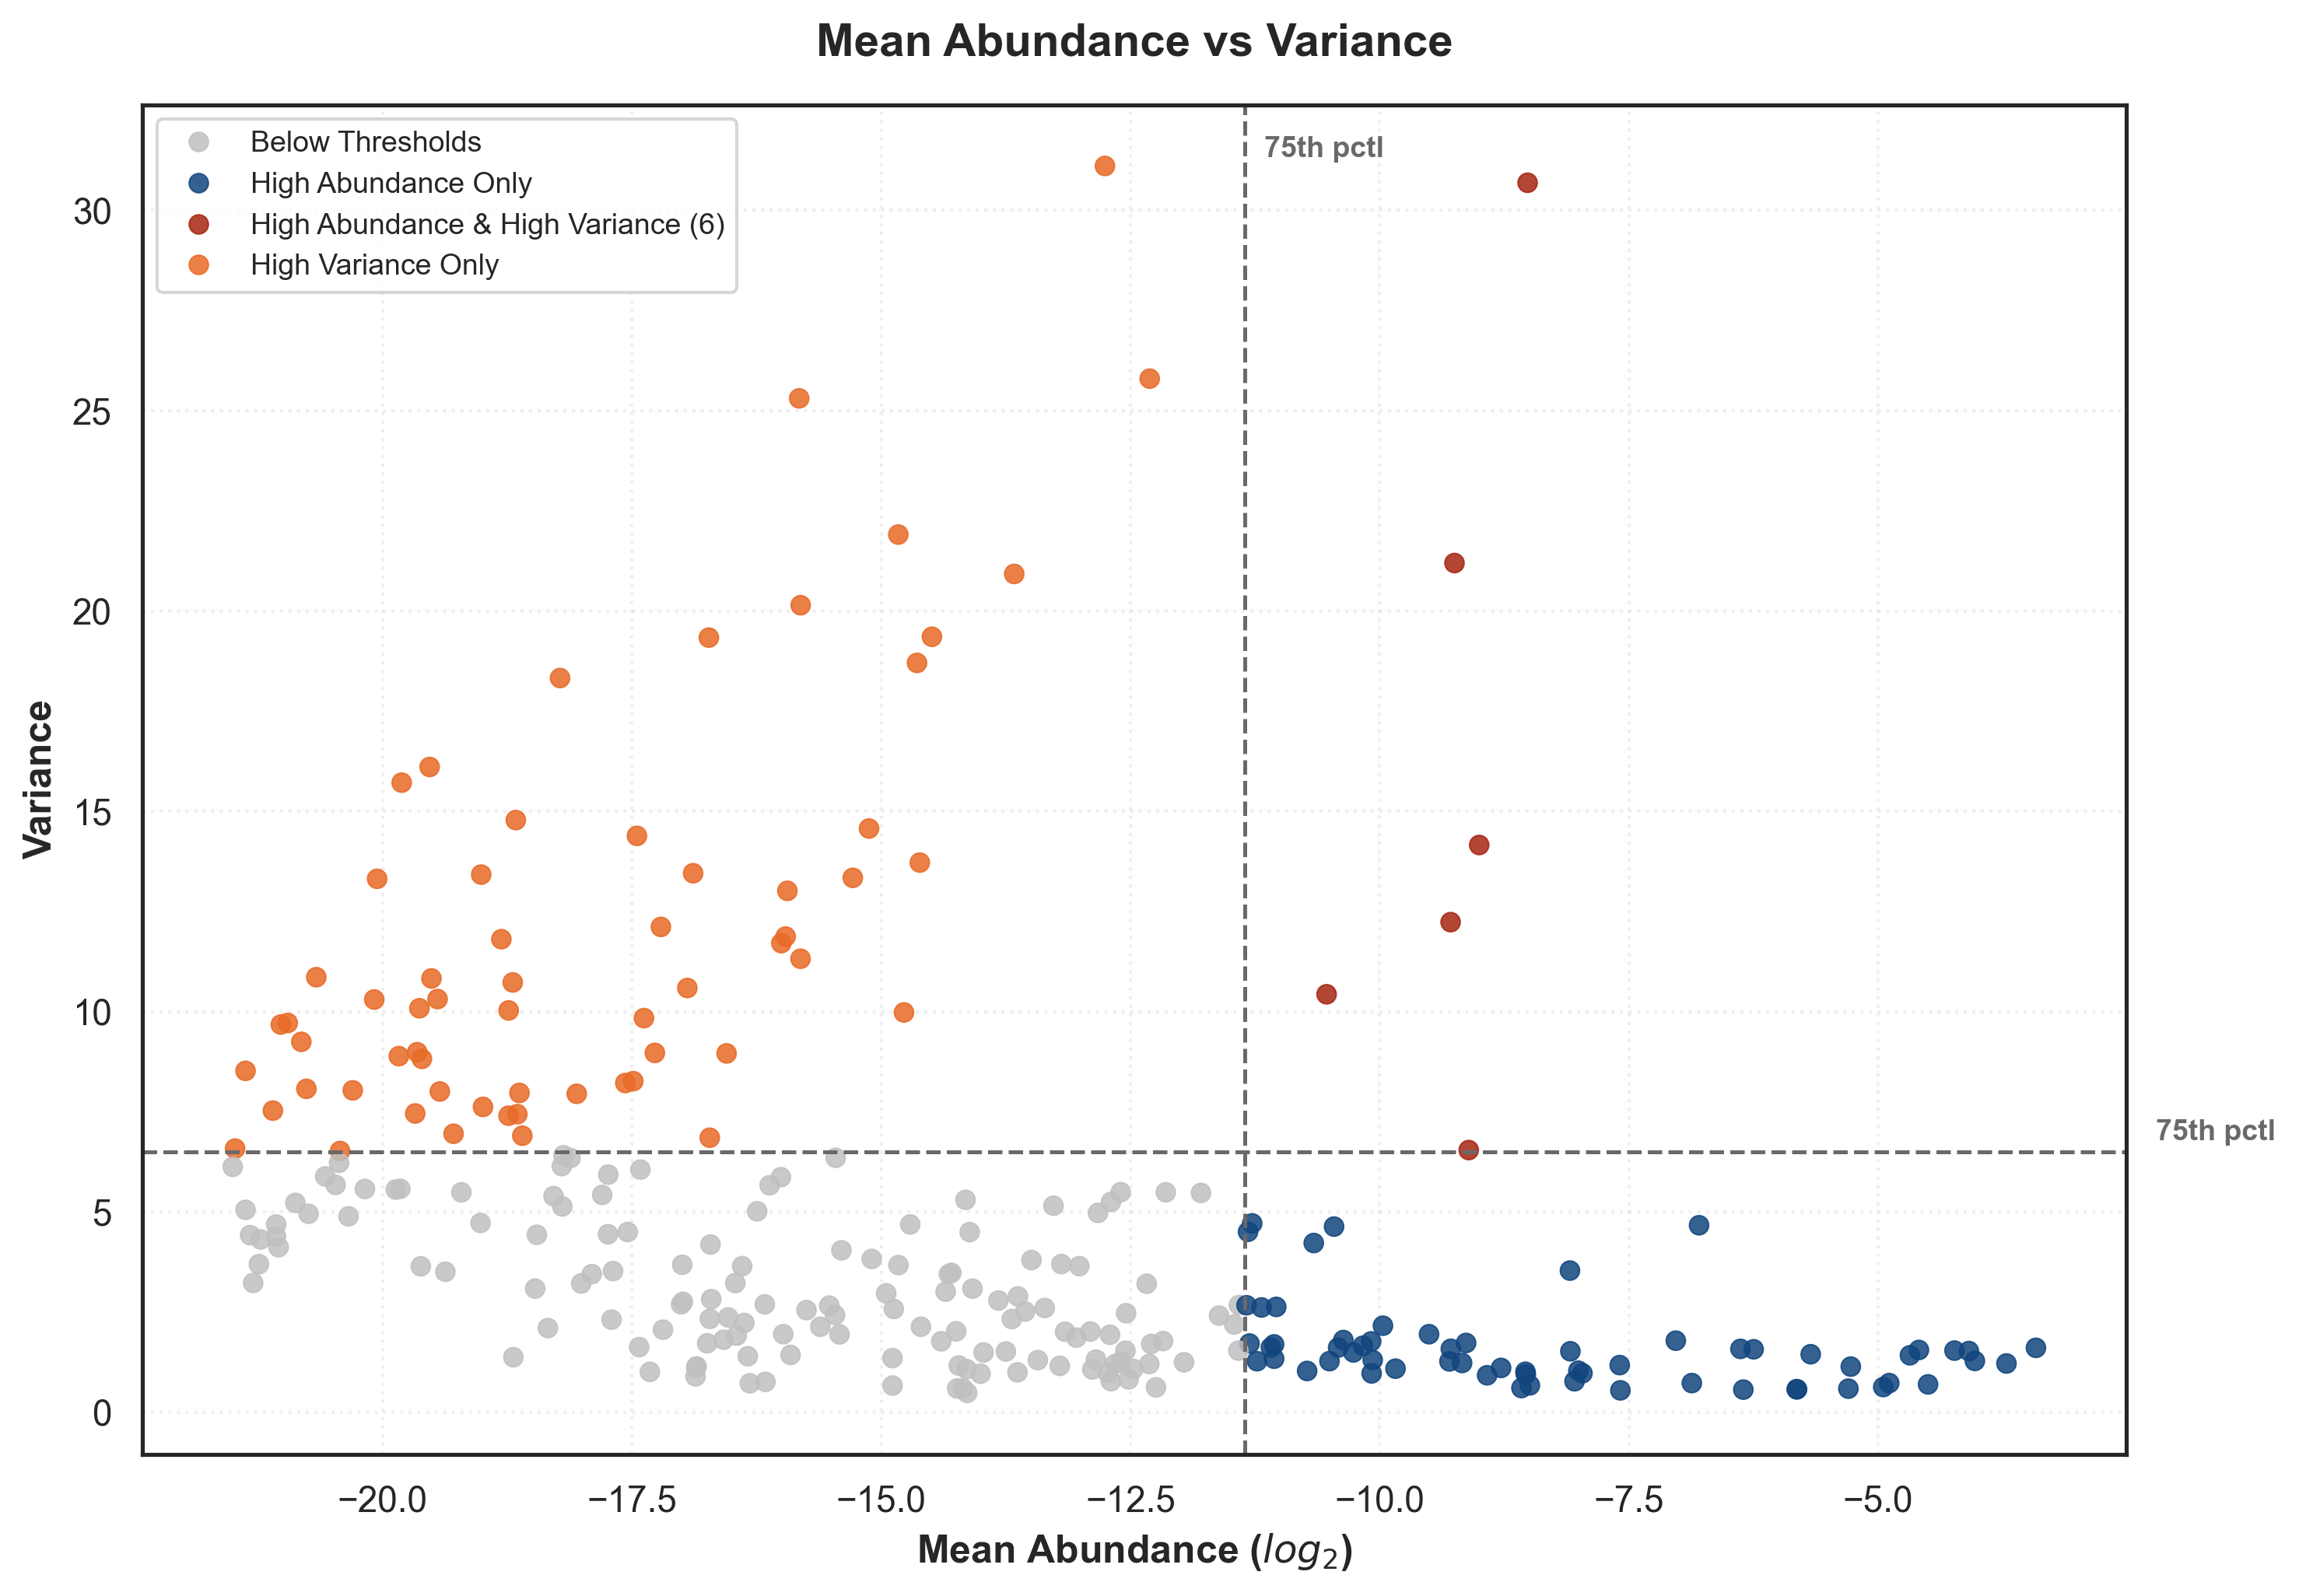

C:\Users\Anas\AppData\Local\Programs\Python\Python310\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\Anas\AppData\Local\Programs\Python\Python310\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\Anas\AppData\Local\Programs\Python\Python310\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


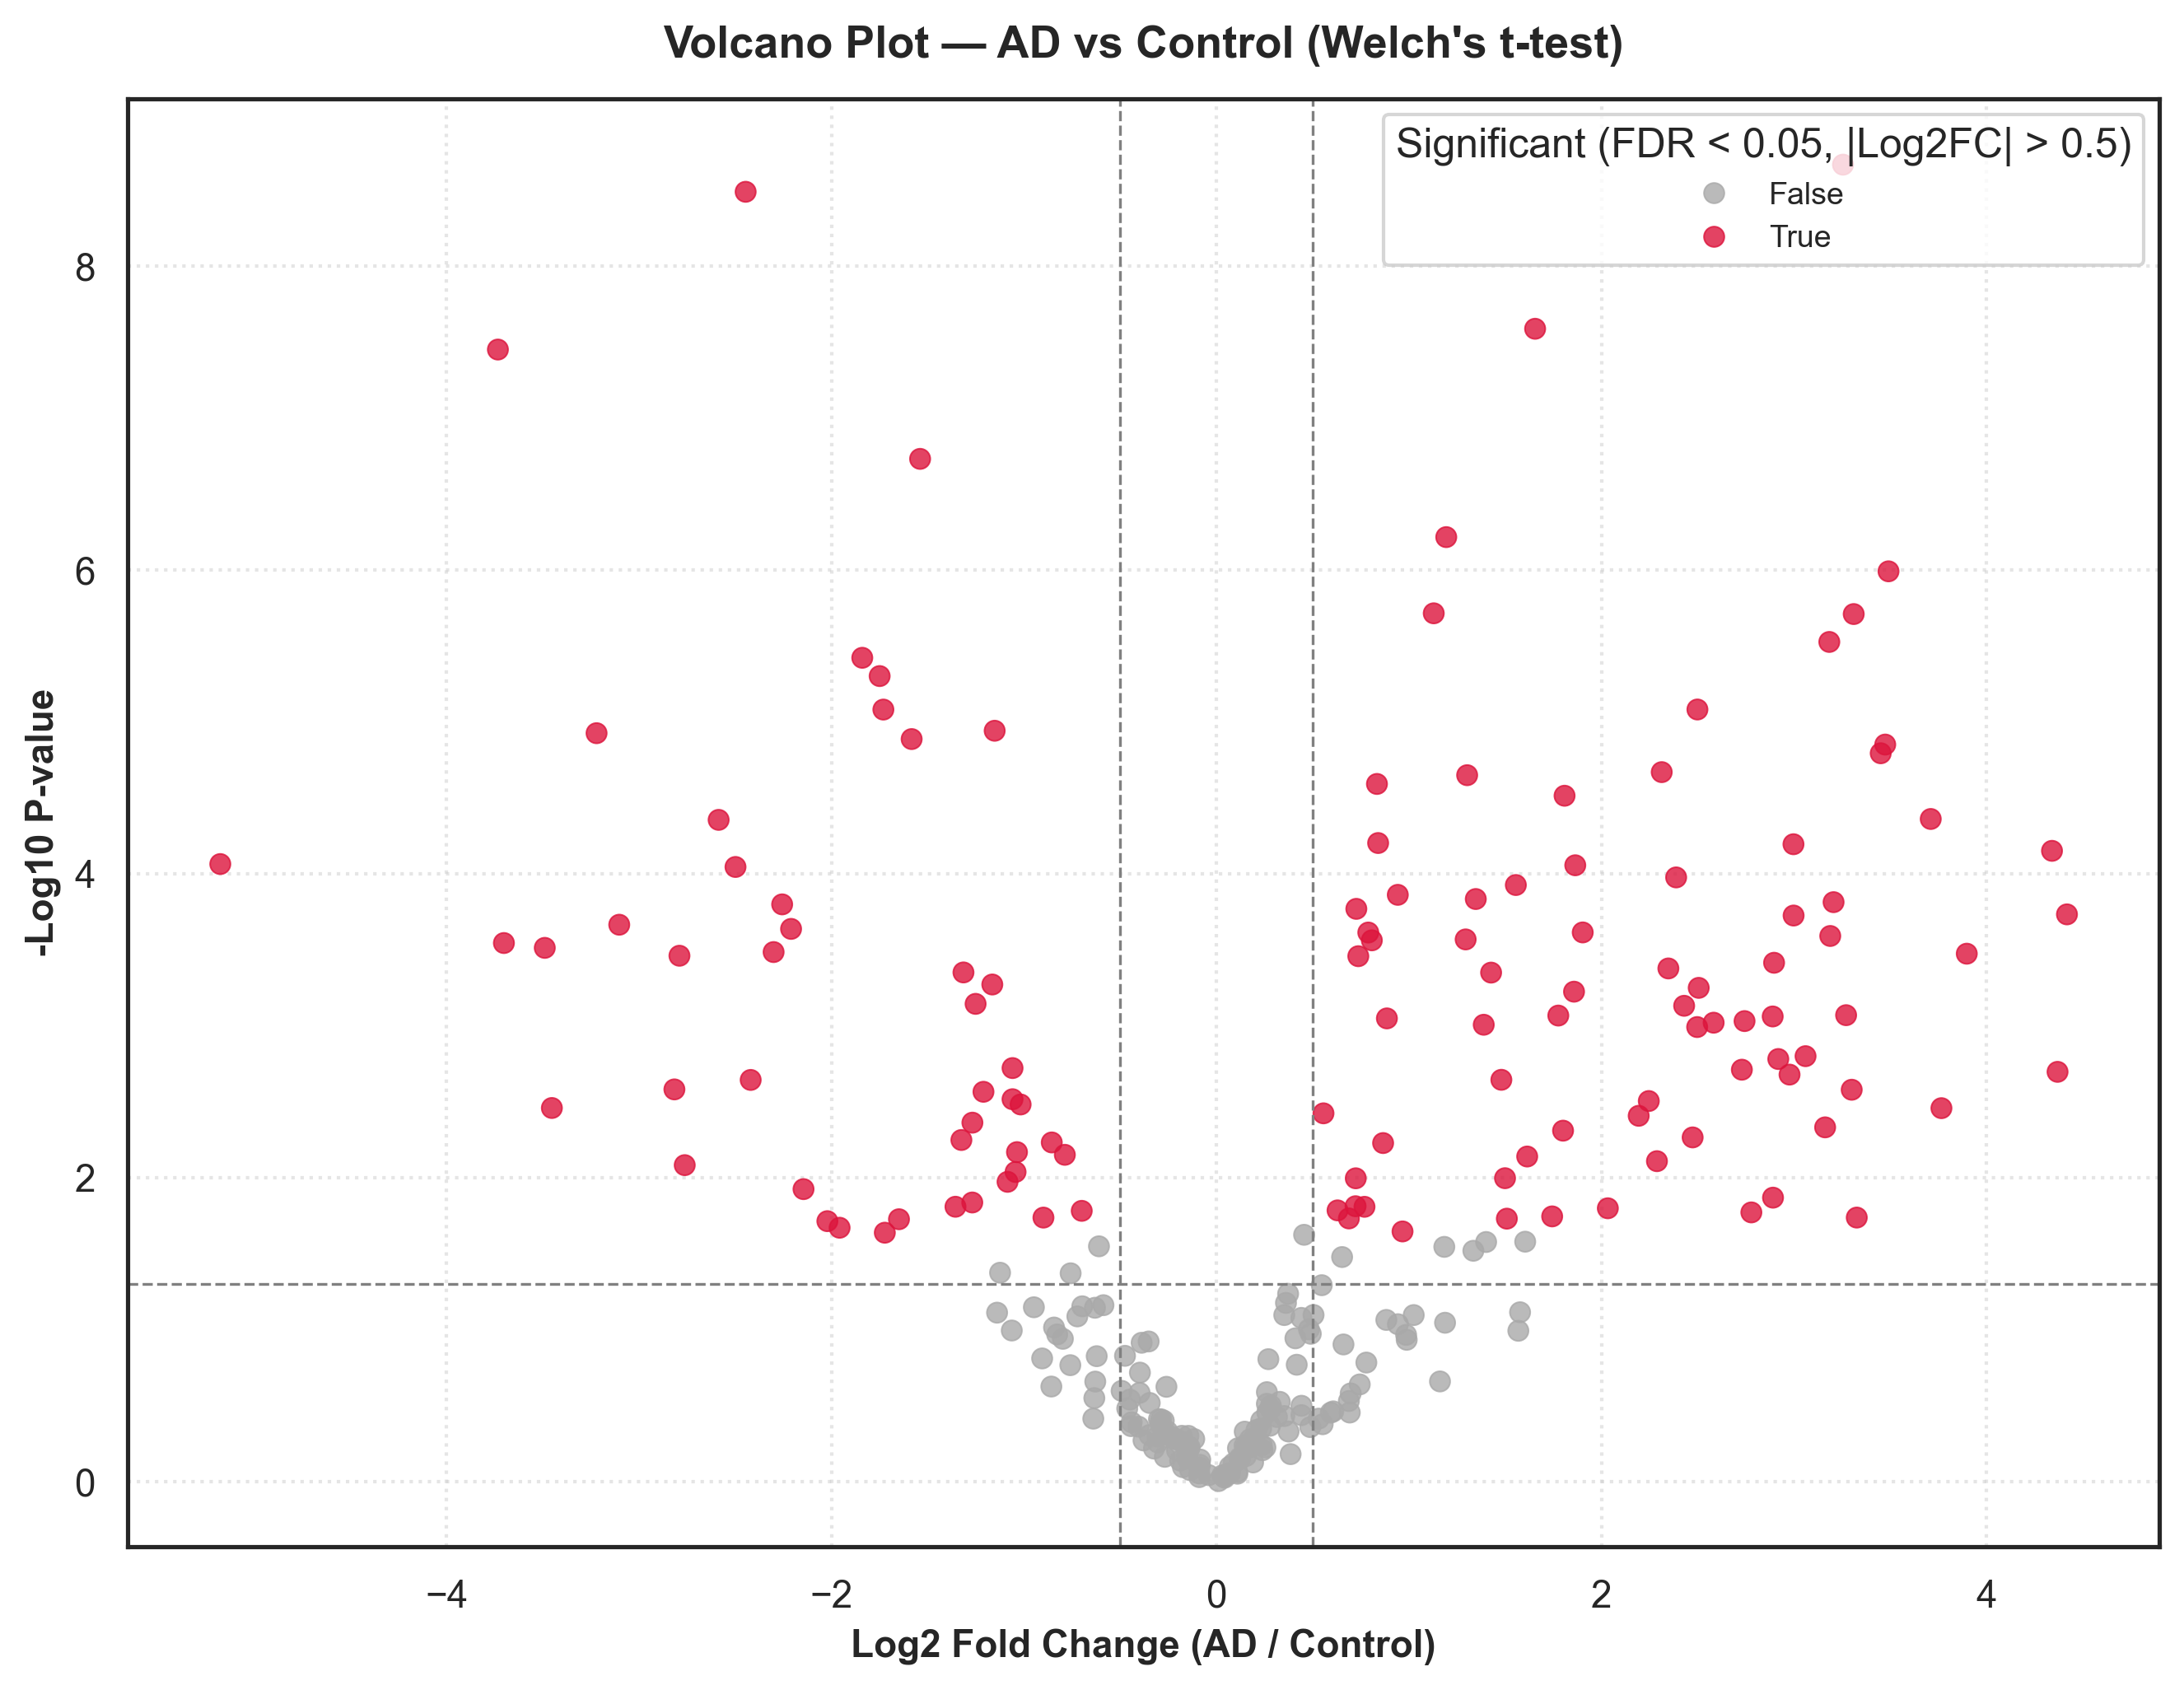

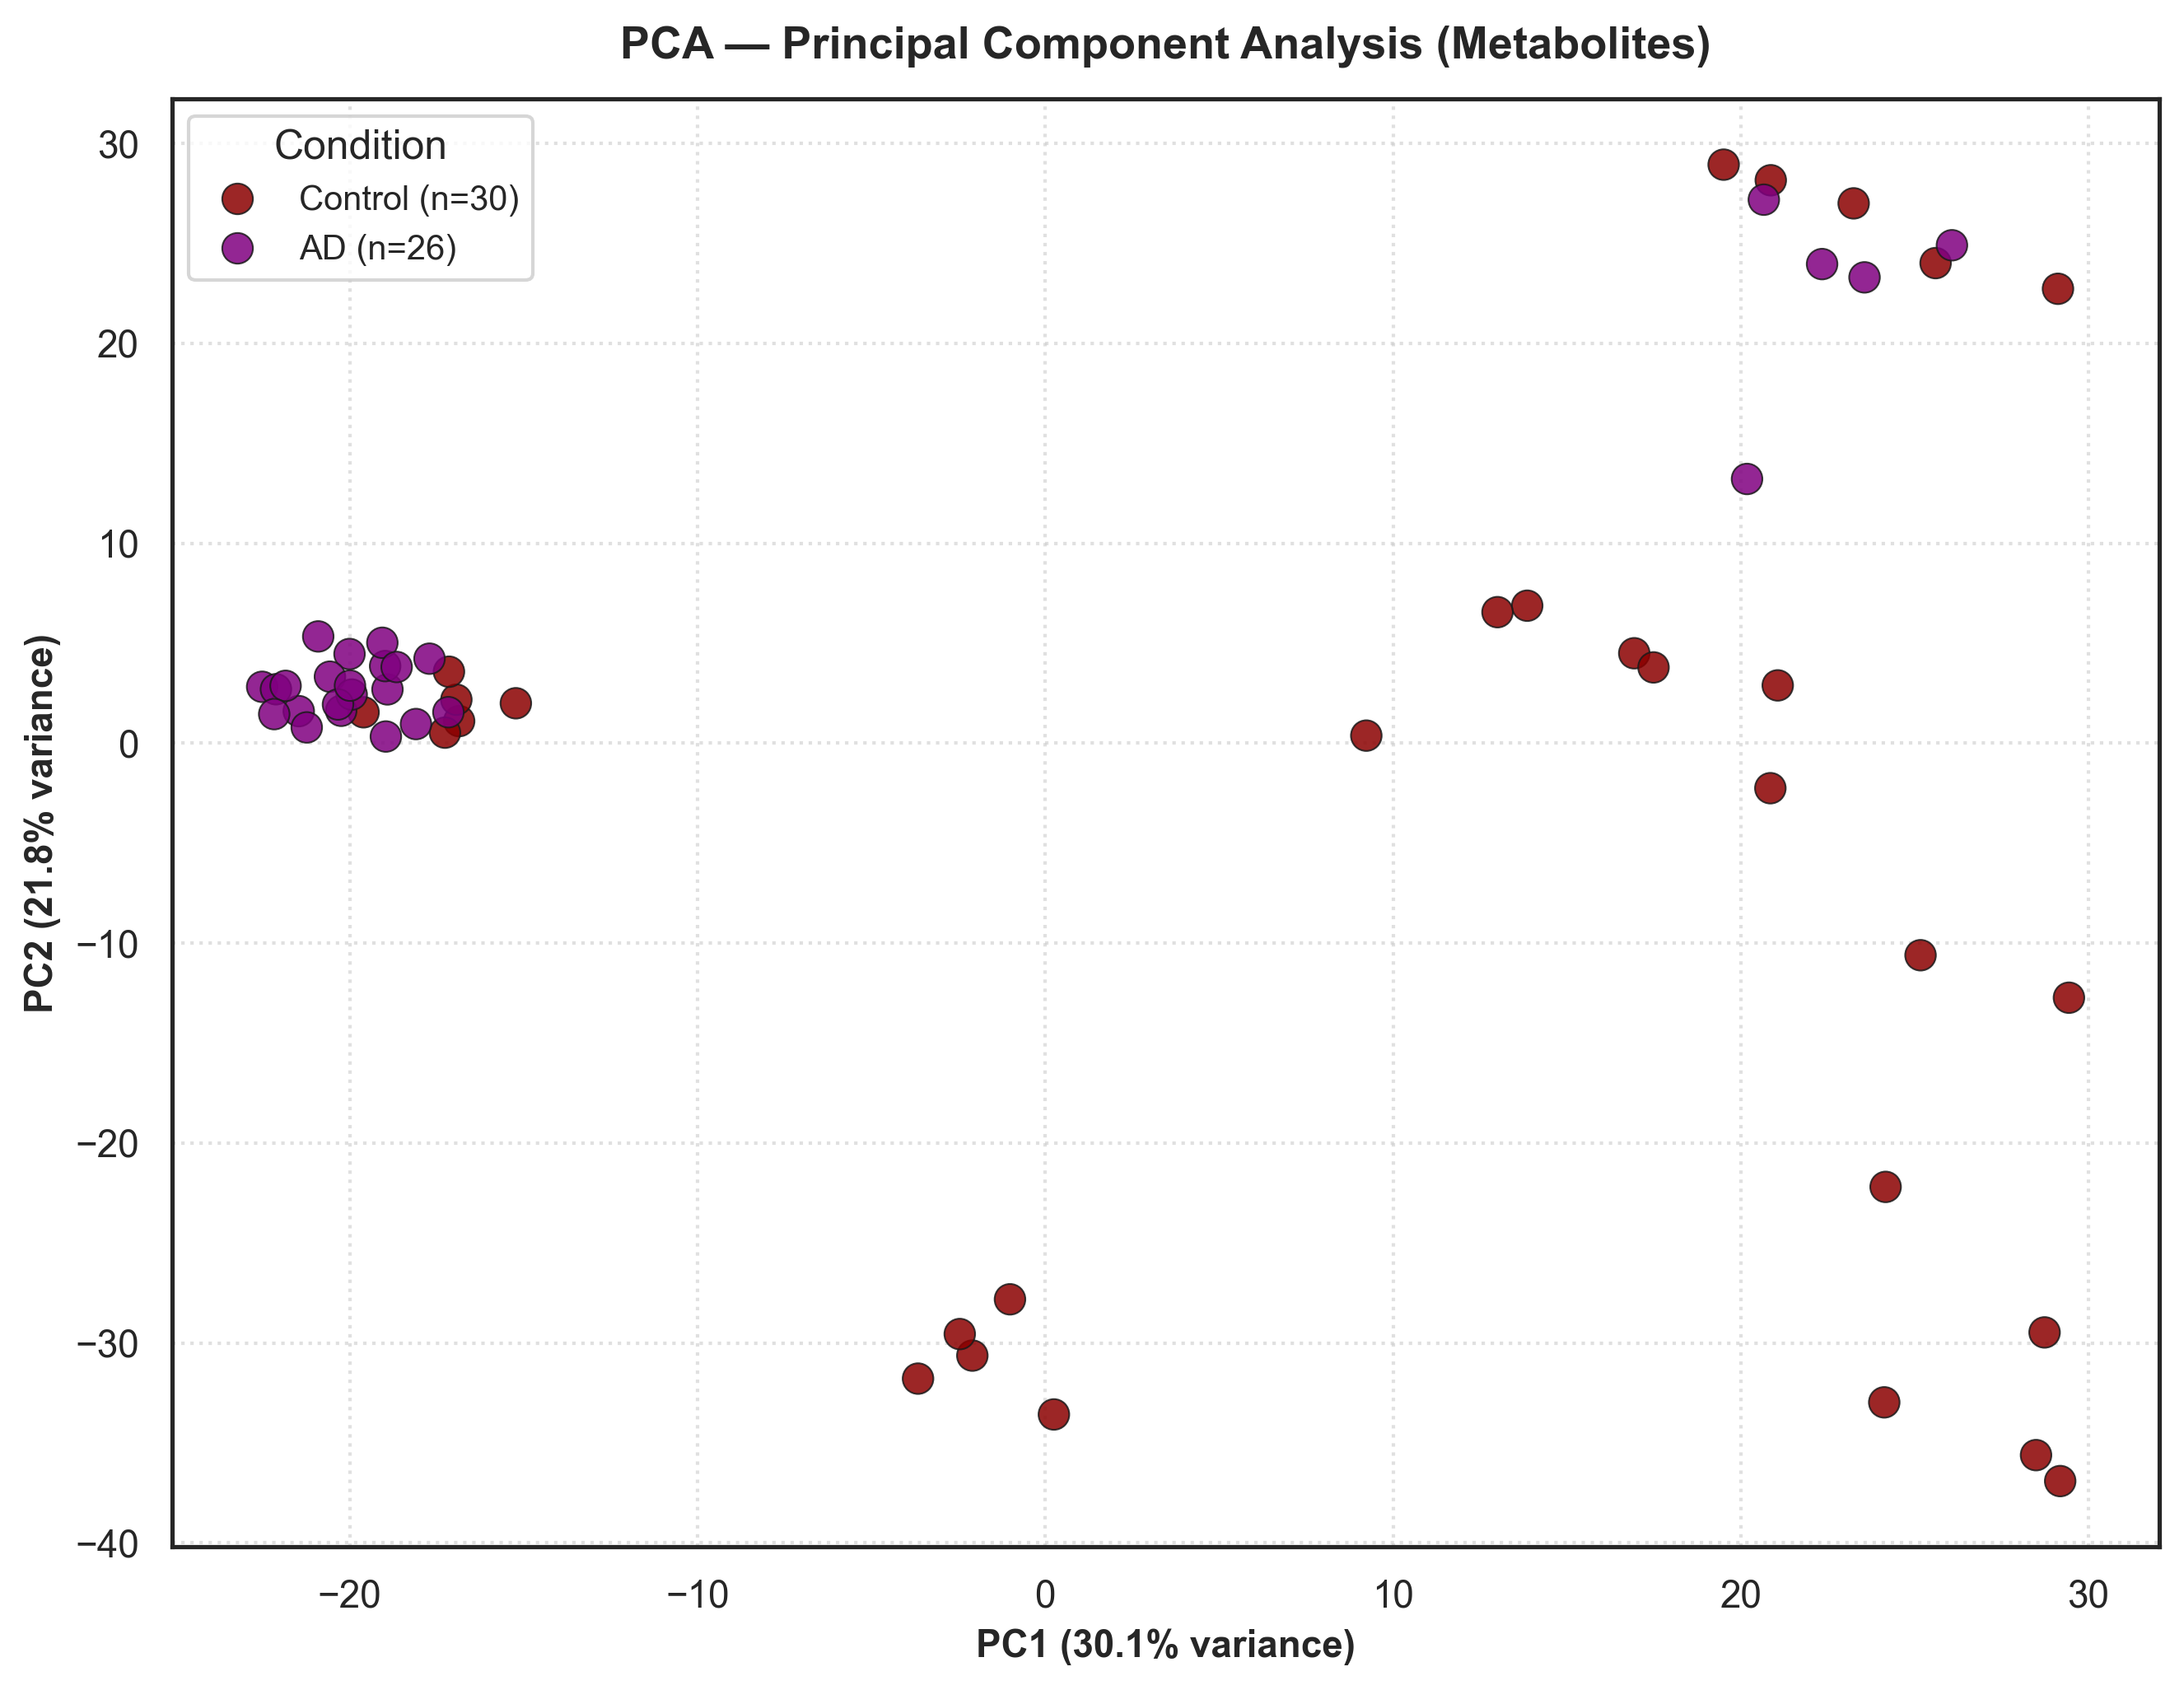

C:\Users\Anas\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


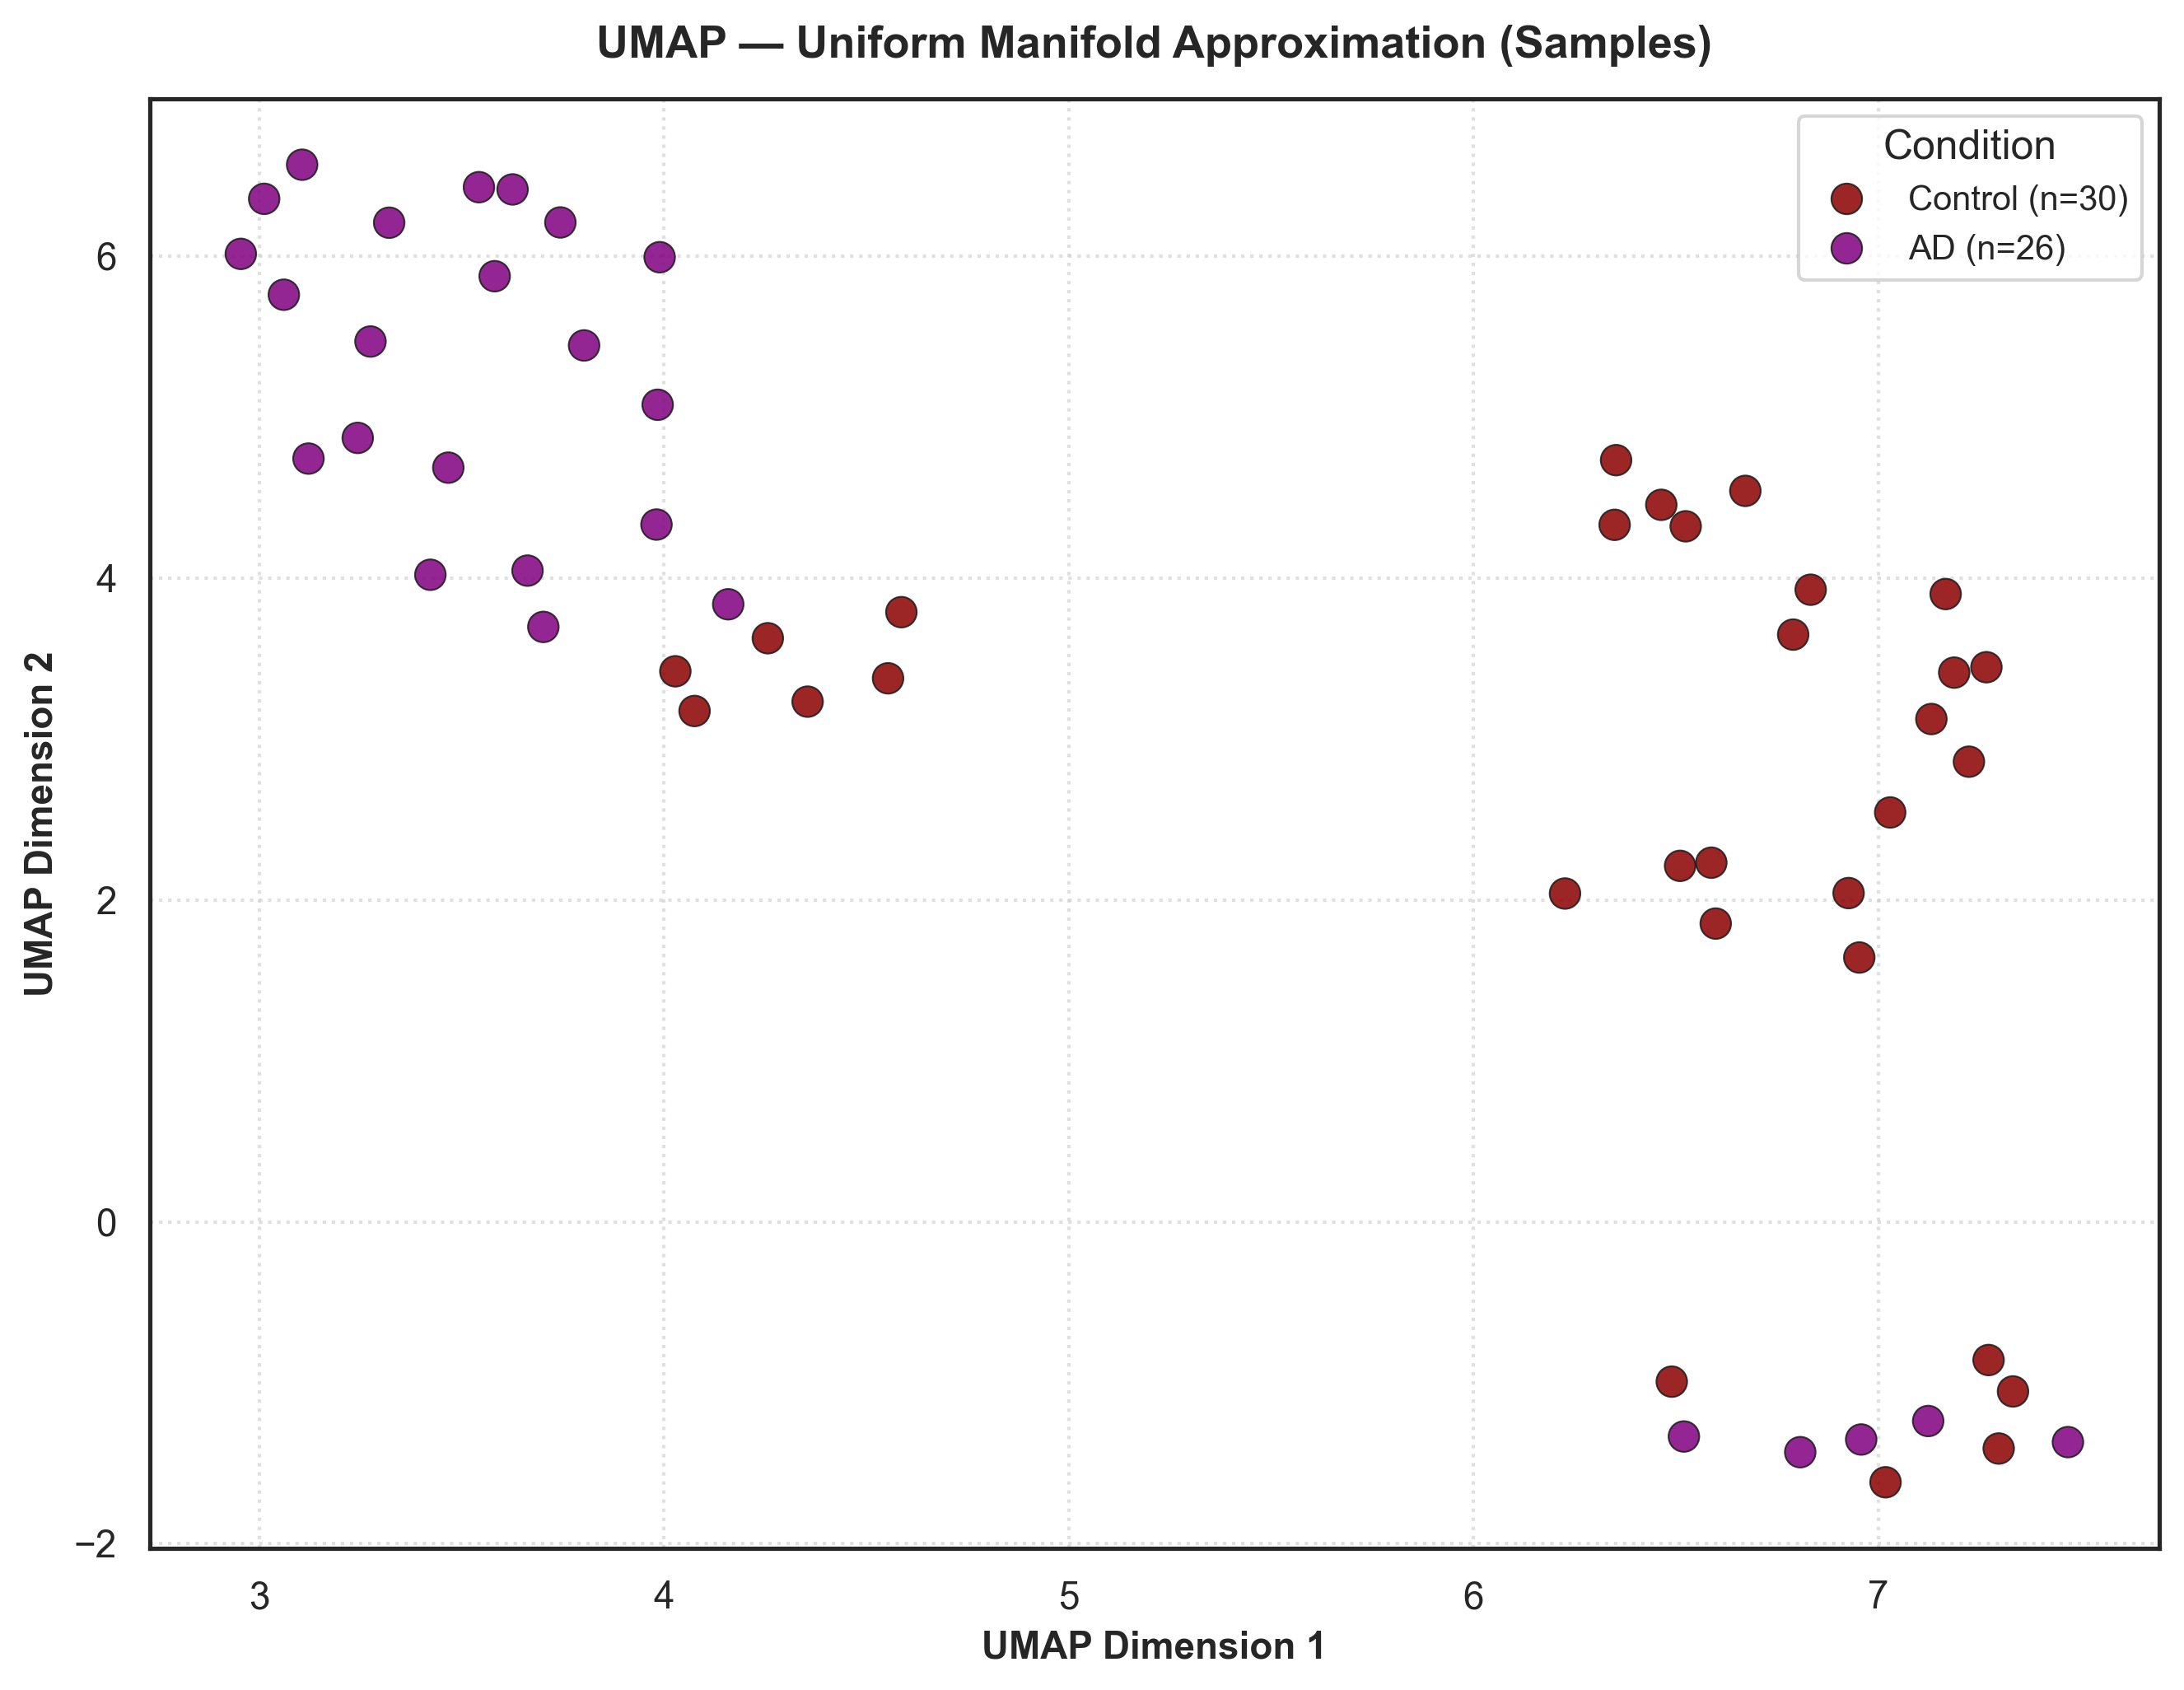

C:\Users\Anas\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


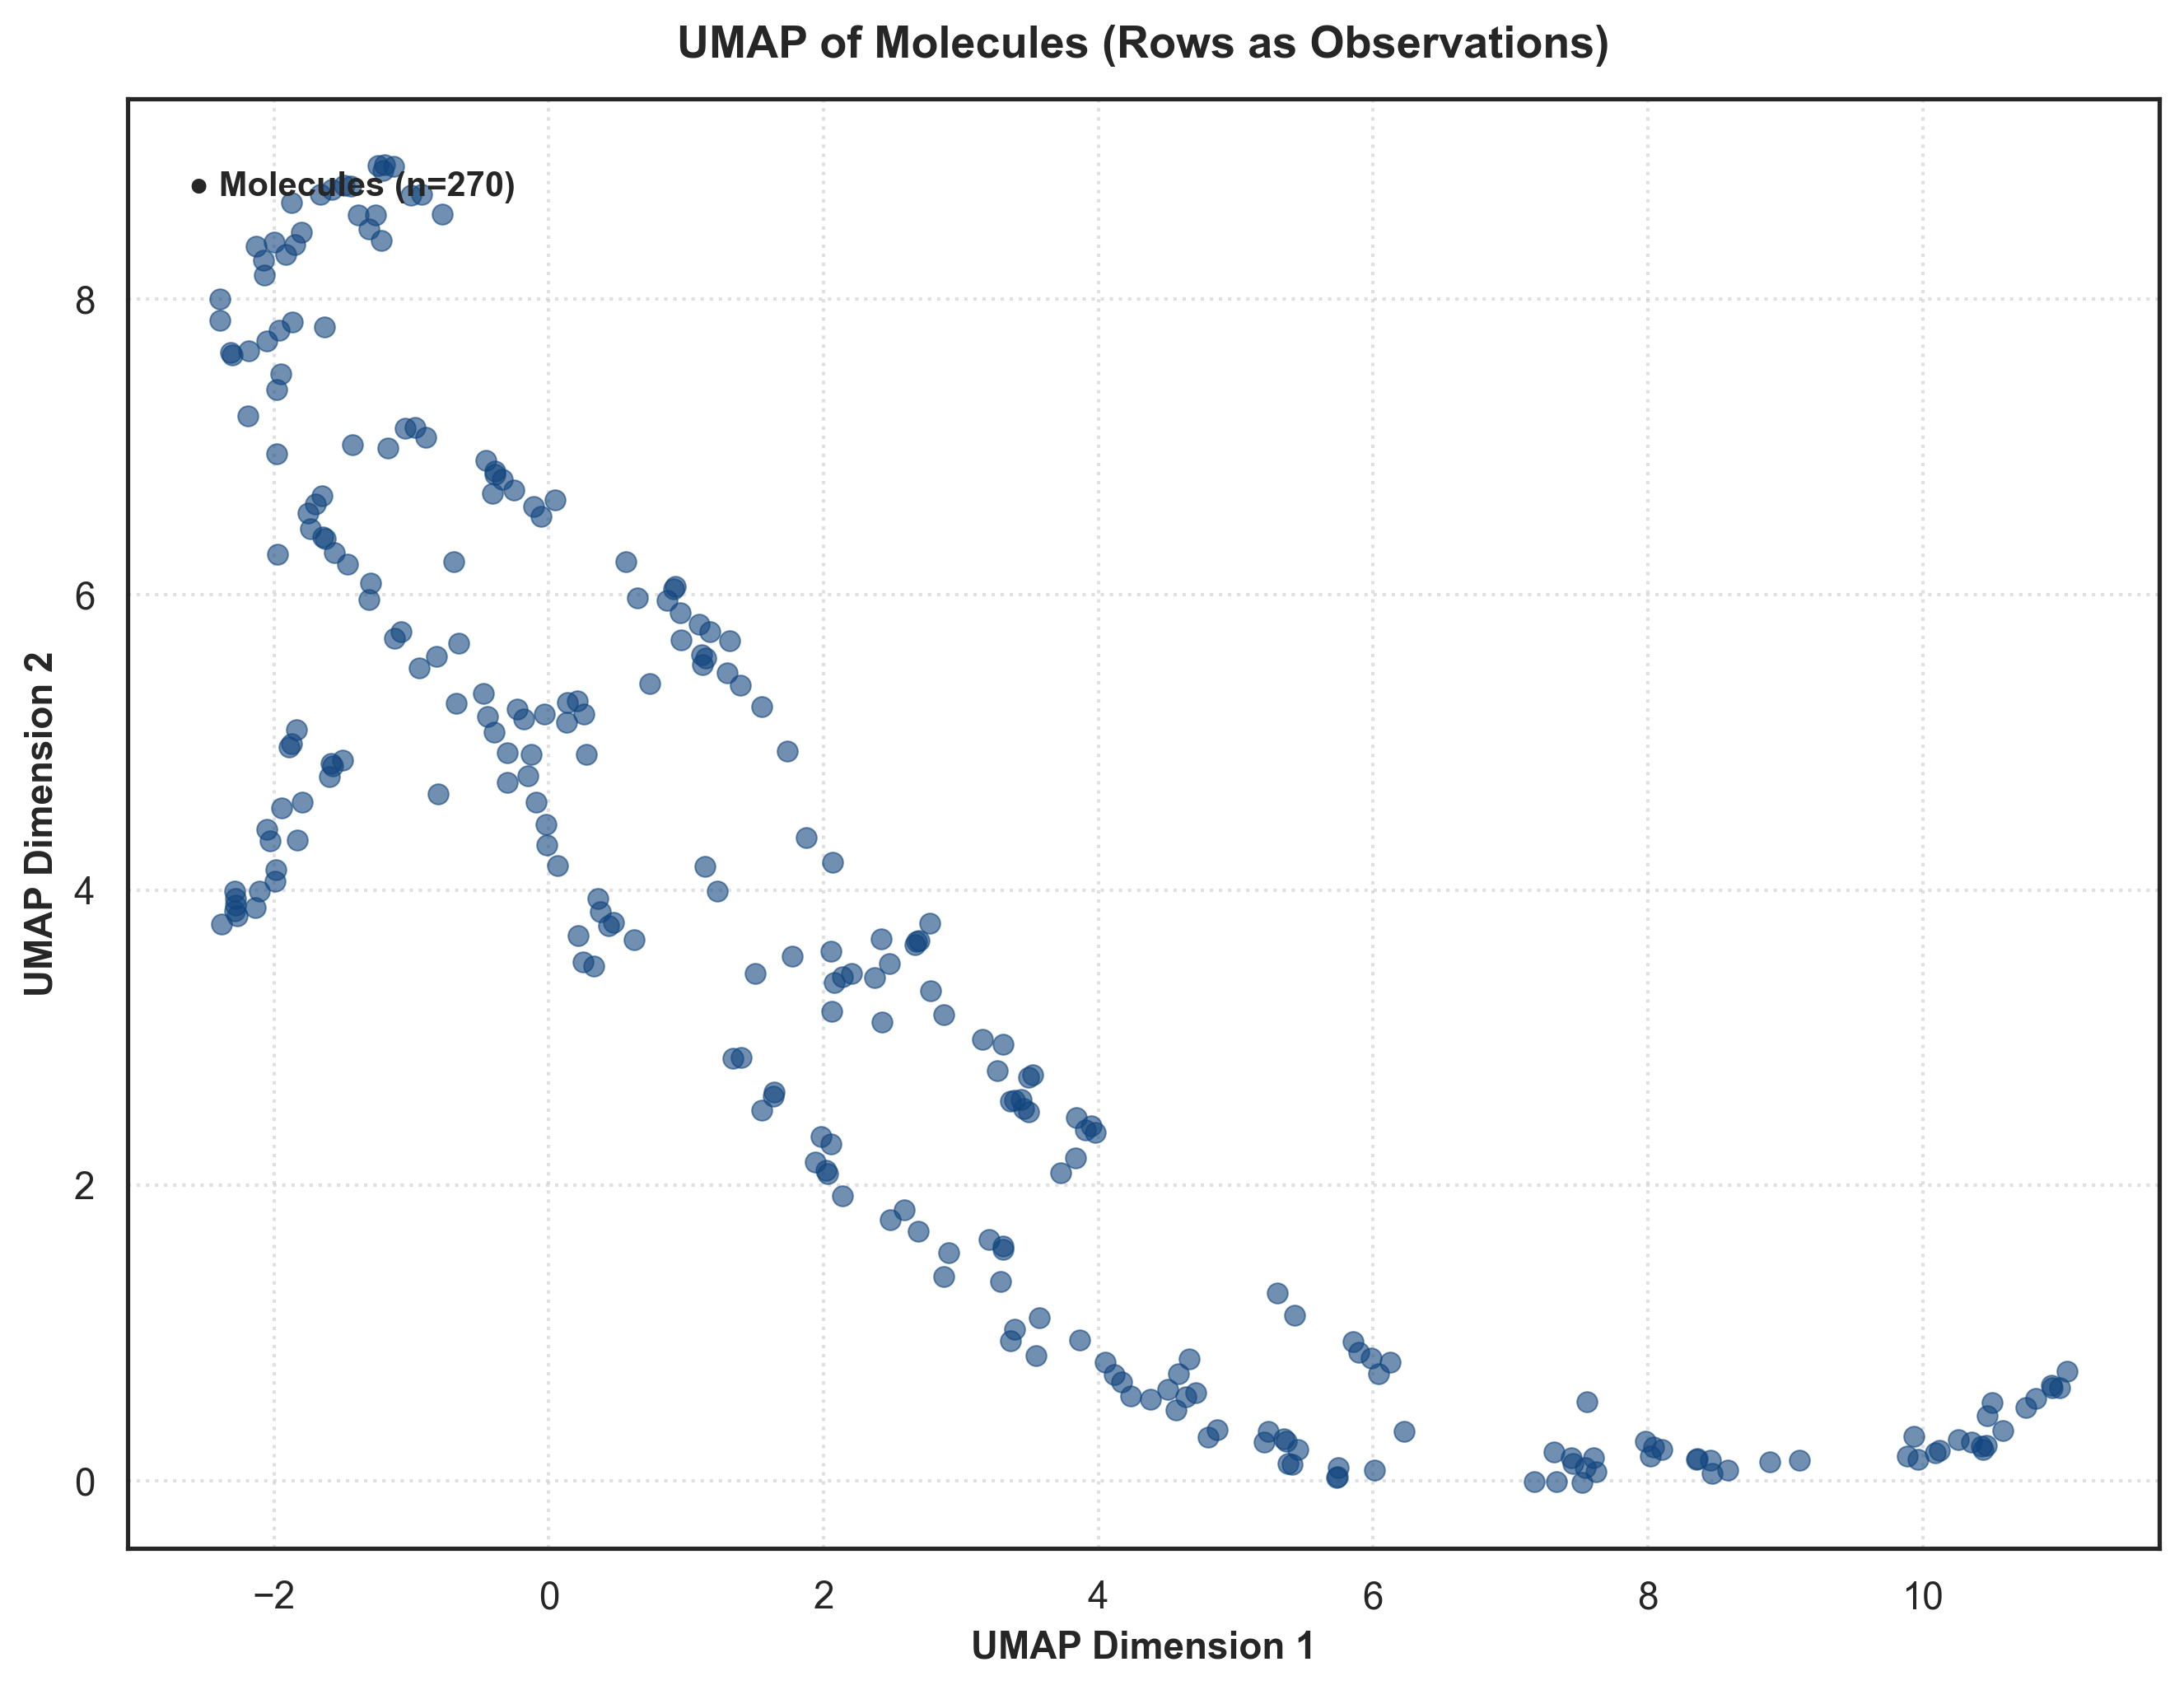

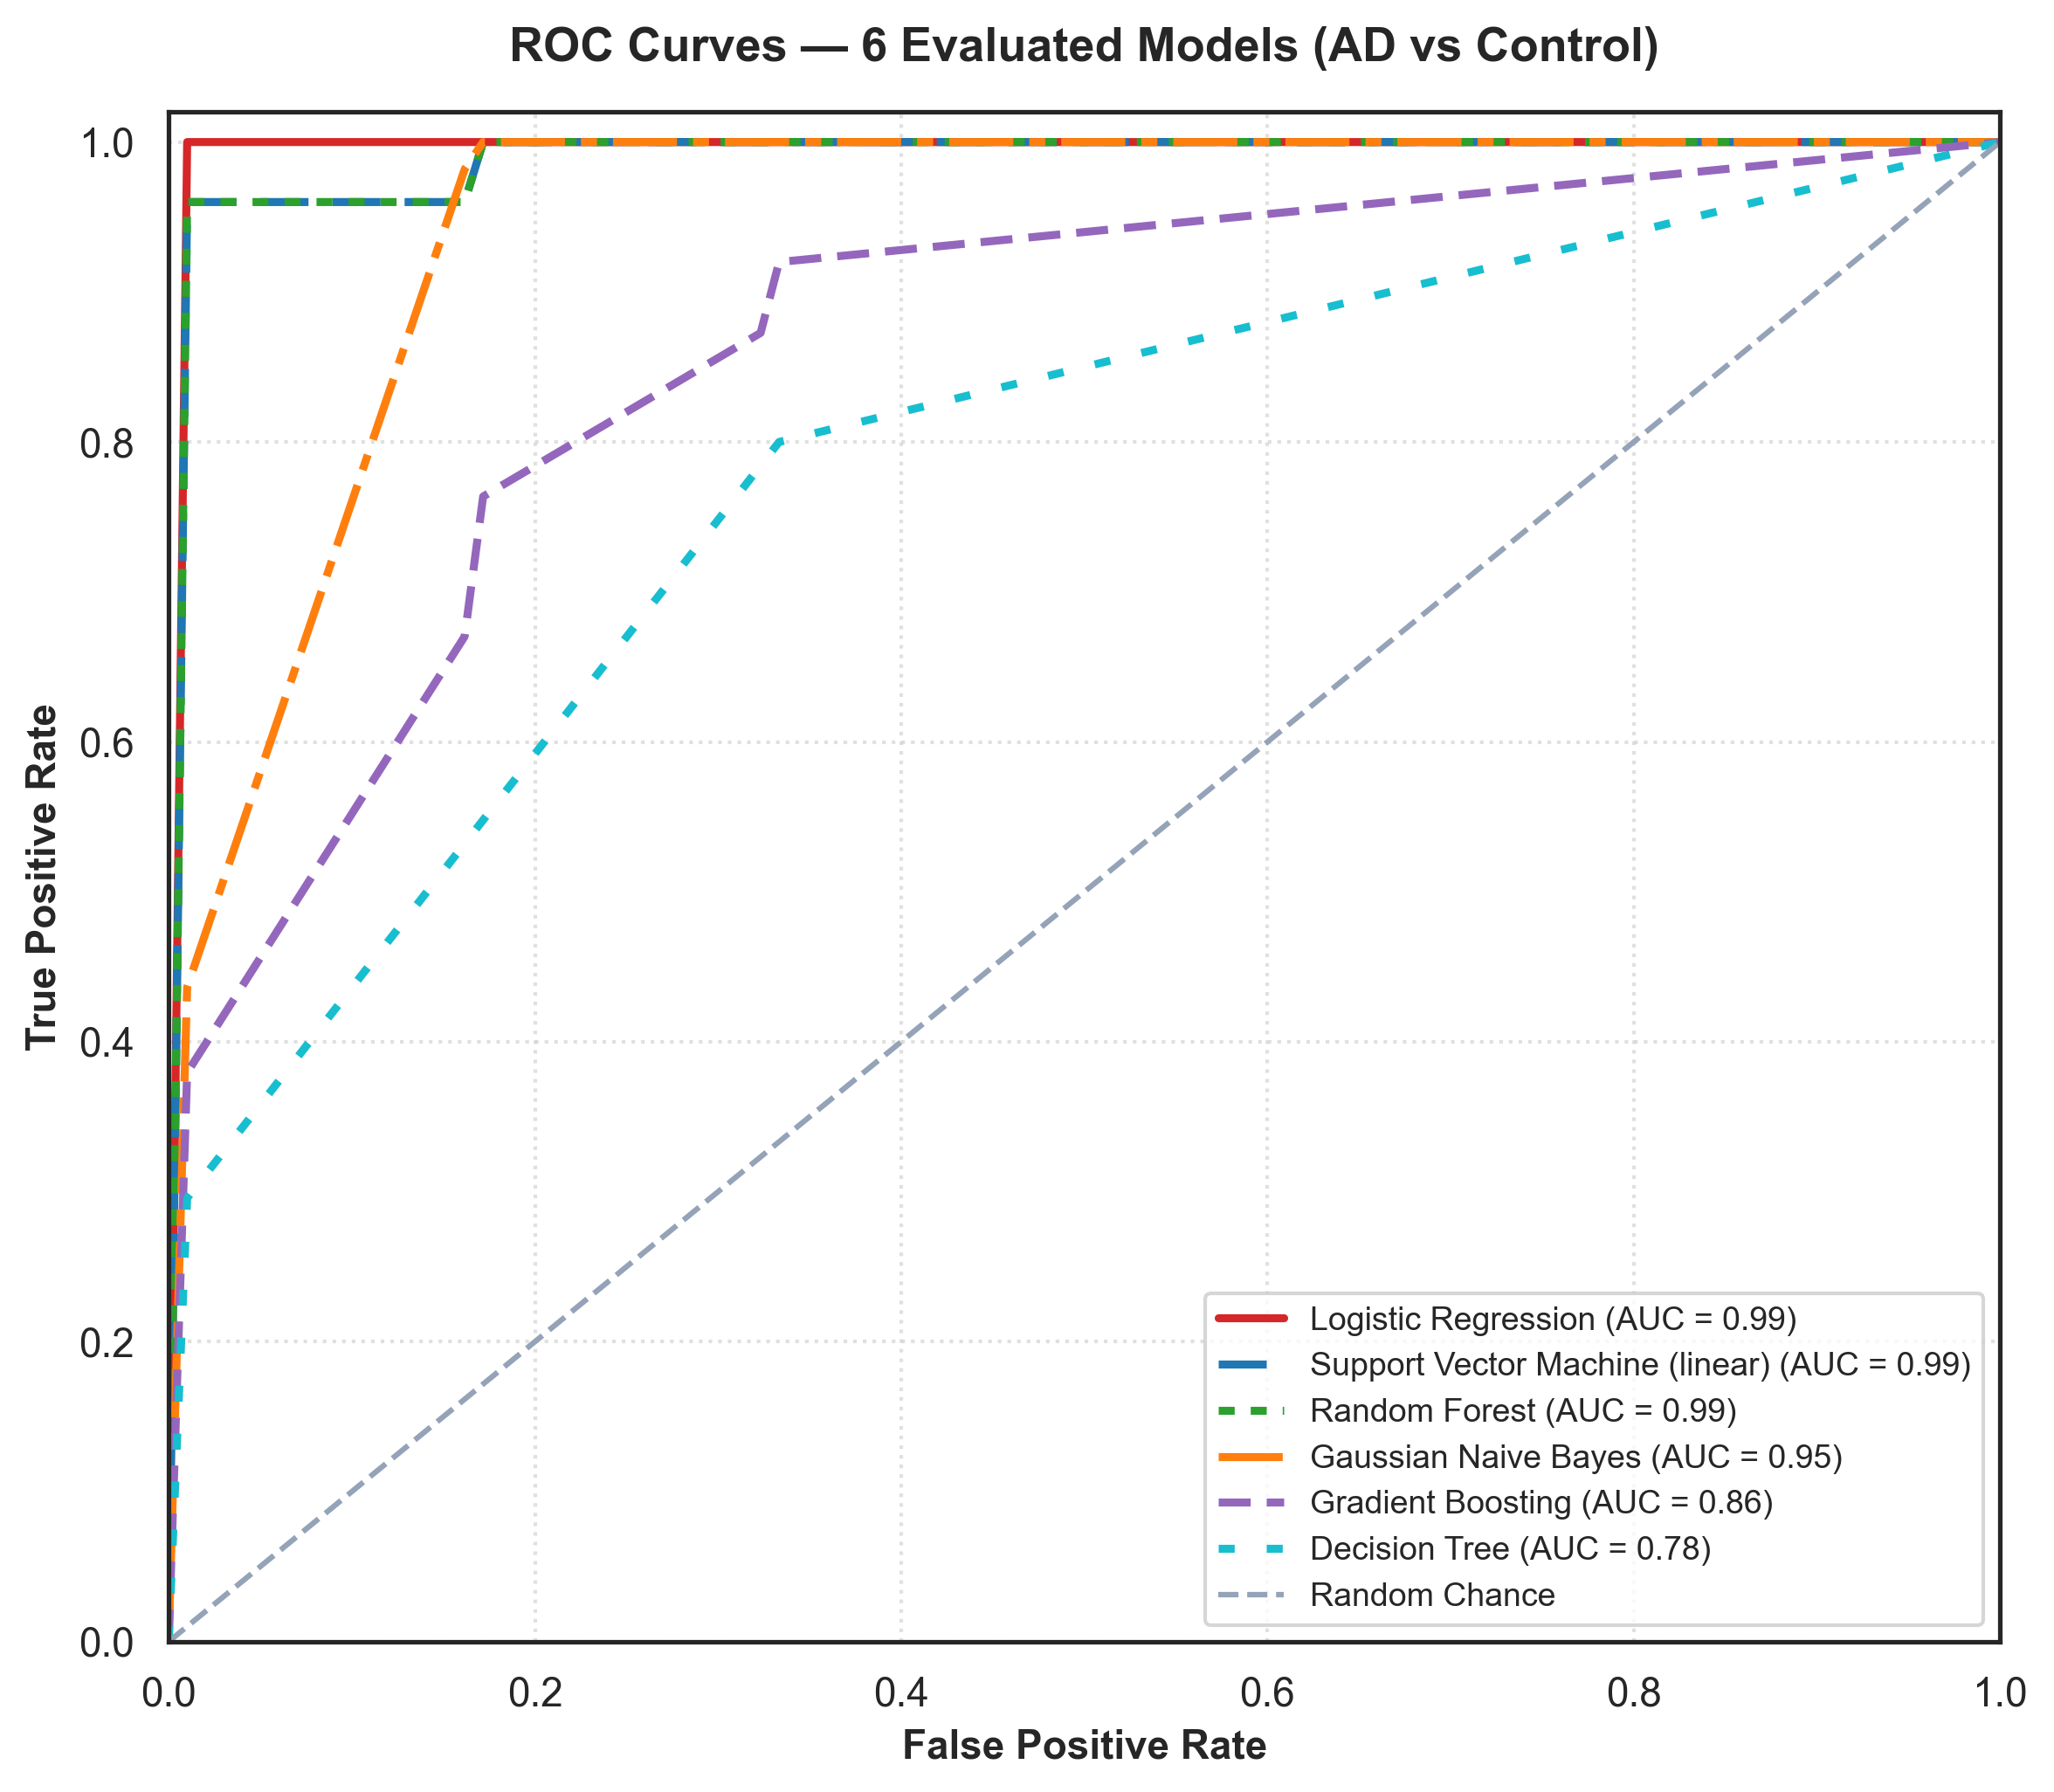

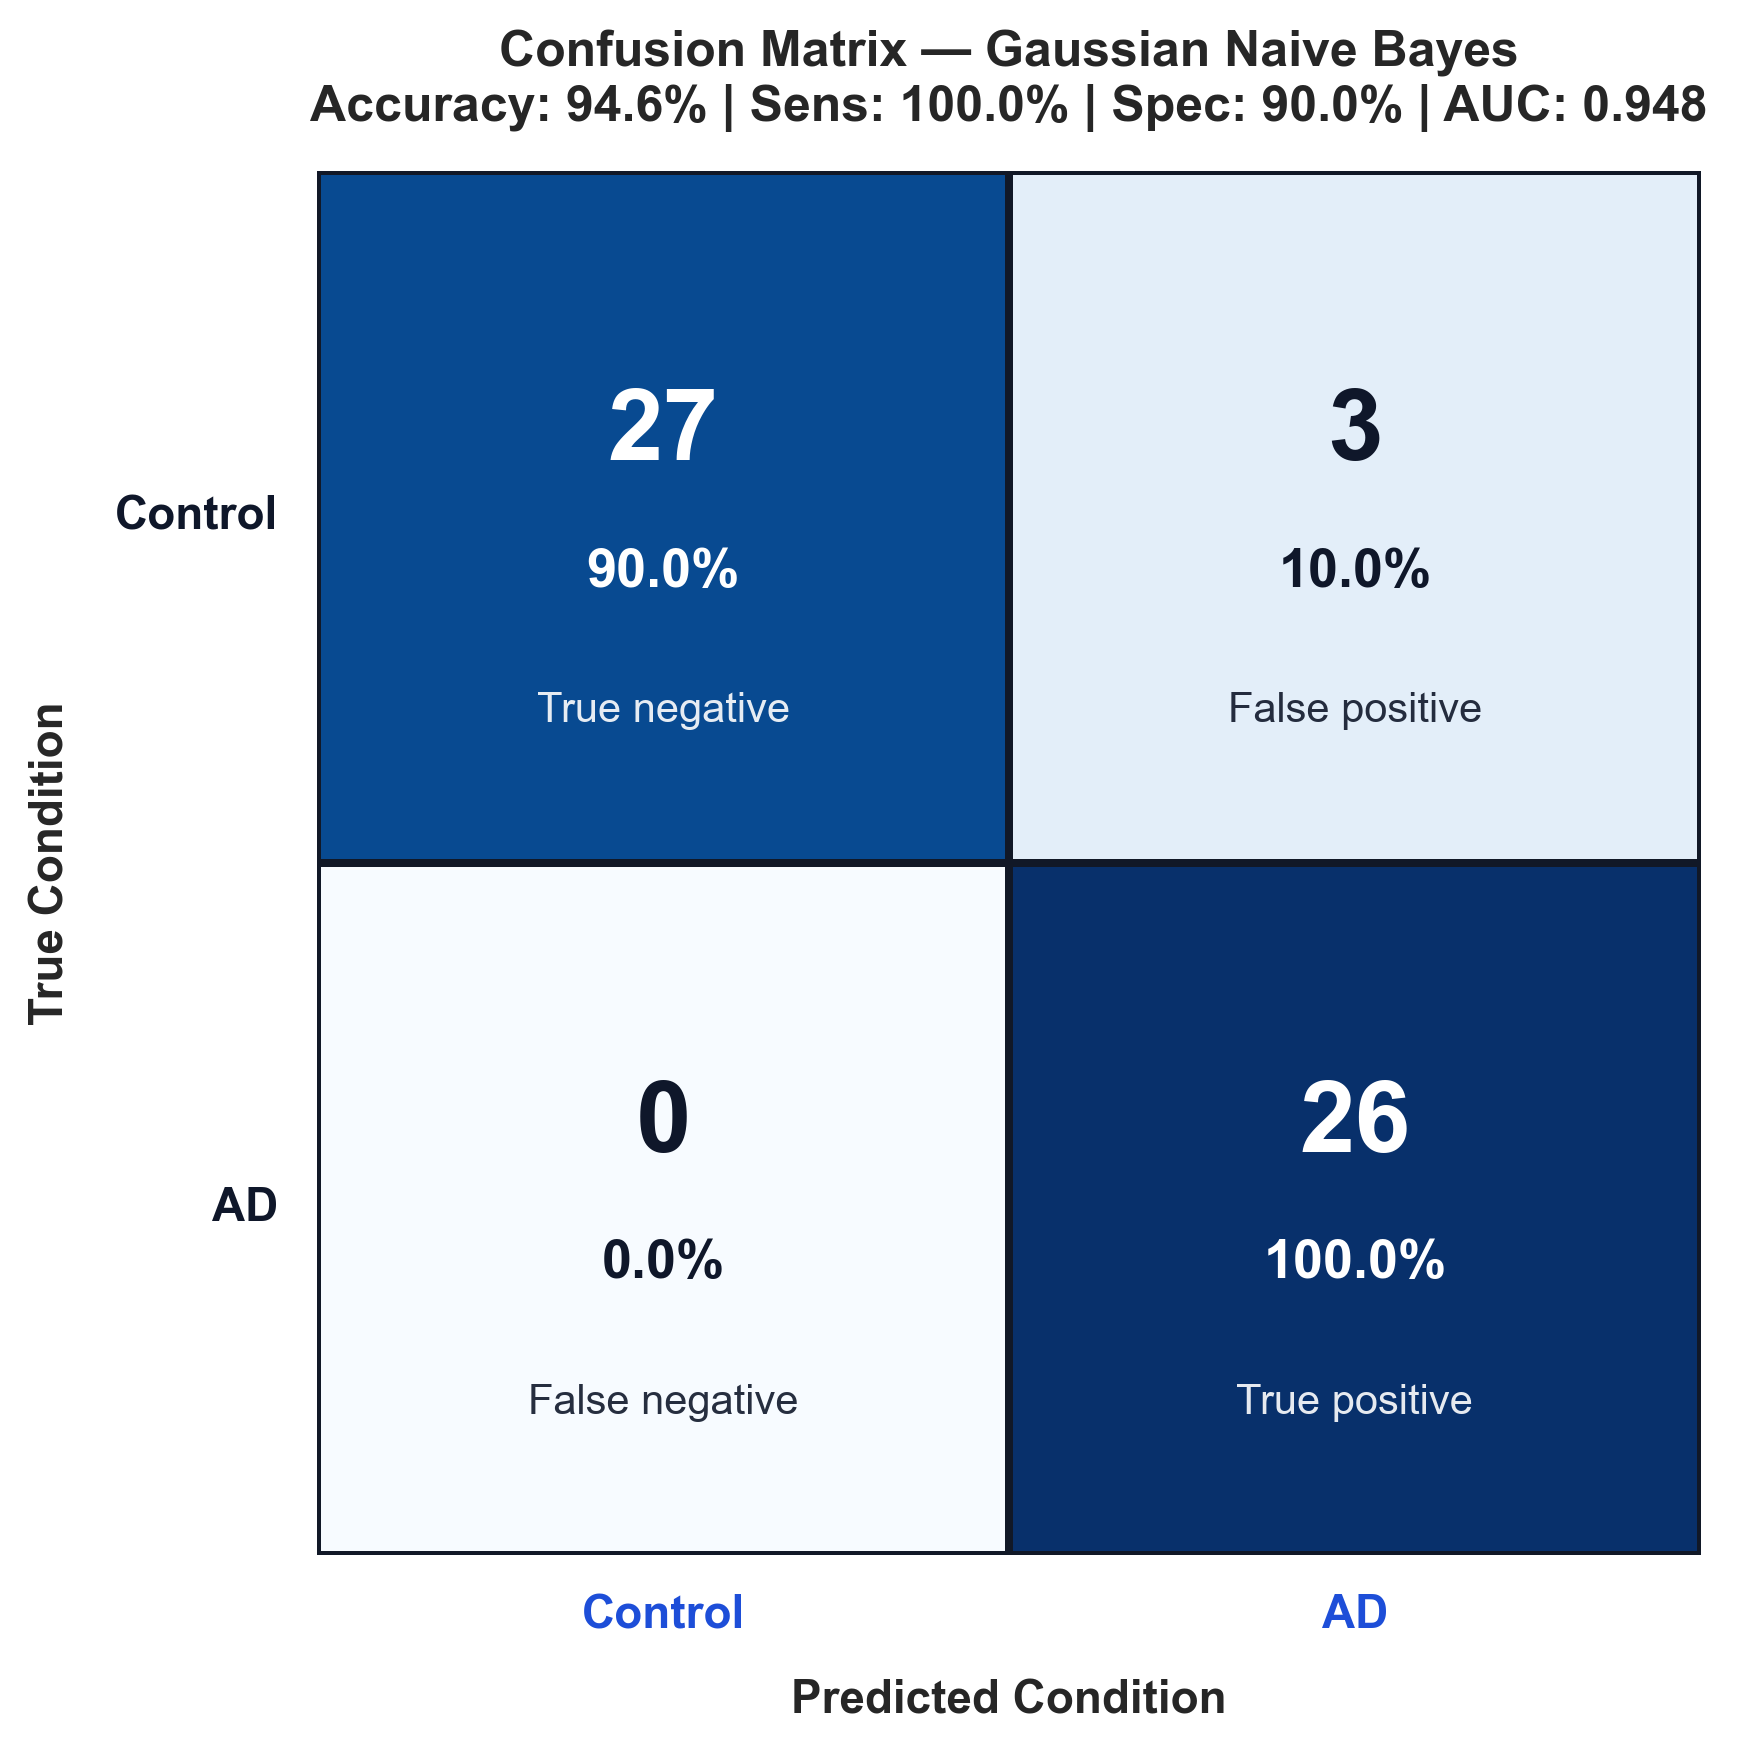

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, auc, accuracy_score, f1_score, confusion_matrix
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
import umap

def run_comprehensive_metabolomics_pipeline(file_path, output_dir="benchmarks"):
    os.makedirs(output_dir, exist_ok=True)
    
    xls = pd.ExcelFile(file_path)
    df = pd.read_excel(file_path, sheet_name='raw data')
    
    sample_cols = [c for c in df.columns if 'Control' in c or 'AD' in c]
    sample_to_group = {c: ('Control' if 'Control' in c else 'AD') for c in sample_cols}
    groups = [sample_to_group[c] for c in sample_cols]
    
    missing_ratio = df[sample_cols].isna().mean(axis=1)
    df_filtered = df[missing_ratio <= 0.90].copy()

    name_col = 'molecules' if 'molecules' in df_filtered.columns else df_filtered.columns[0]
    df_filtered[sample_cols] = df_filtered[sample_cols].fillna(0)

    log2_data = np.log2(df_filtered[sample_cols].replace(0, np.nan))
    min_val = log2_data.min().min() if not log2_data.min().empty else 0
    log2_data = log2_data.fillna(min_val)

    row_mean = log2_data[sample_cols].mean(axis=1)
    row_std = log2_data[sample_cols].std(axis=1)
    z_row_wise = log2_data[sample_cols].sub(row_mean, axis=0).div(row_std, axis=0).fillna(0)

    plt.figure(figsize=(18, 5), dpi=300)
    sns.set_theme(style="white")
    sns.boxplot(data=z_row_wise, palette="coolwarm", fliersize=1, linewidth=0.5)
    plt.title("Z-score Distribution Across Samples", fontsize=12, fontweight='bold', pad=12)
    plt.xlabel("Samples", fontsize=10, fontweight='bold')
    plt.ylabel("Abundance (z-score)", fontsize=10, fontweight='bold')
    plt.xticks(rotation=90, fontsize=4)
    plt.yticks(fontsize=9)
    plt.grid(axis='y', linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "zscore_distribution_metabolites.png"), dpi=300, bbox_inches='tight')
    plt.show()

    mean_ab = log2_data[sample_cols].mean(axis=1)
    var_ab = log2_data[sample_cols].var(axis=1)
    df_filtered['mean_ab'] = mean_ab
    df_filtered['var_ab'] = var_ab
    mean_thresh = mean_ab.quantile(0.75)
    var_thresh = var_ab.quantile(0.75)
    df_filtered['category'] = 'Below Thresholds'
    df_filtered.loc[(df_filtered['mean_ab'] >= mean_thresh) & (df_filtered['var_ab'] < var_thresh), 'category'] = 'High Abundance Only'
    df_filtered.loc[(df_filtered['mean_ab'] < mean_thresh) & (df_filtered['var_ab'] >= var_thresh), 'category'] = 'High Variance Only'
    high_high_mask = (df_filtered['mean_ab'] >= mean_thresh) & (df_filtered['var_ab'] >= var_thresh)
    df_filtered.loc[high_high_mask, 'category'] = 'High Abundance & High Variance'
    high_high_count = high_high_mask.sum()

    plt.figure(figsize=(10, 7), dpi=300)
    palette = {
        'Below Thresholds': '#C0C0C0',
        'High Abundance Only': '#11457E',
        'High Variance Only': '#E86A27',
        'High Abundance & High Variance': '#A62612'
    }
    sns.scatterplot(
        data=df_filtered, x='mean_ab', y='var_ab', hue='category',
        palette=palette, s=35, alpha=0.85, edgecolor=None
    )
    plt.axvline(mean_thresh, color='dimgrey', linestyle='--', linewidth=1.2)
    plt.axhline(var_thresh, color='dimgrey', linestyle='--', linewidth=1.2)
    plt.text(mean_thresh + 0.2, plt.ylim()[1] * 0.96, '75th pctl', color='dimgrey', fontsize=9, fontweight='bold')
    plt.text(plt.xlim()[1] * 0.88, var_thresh + 0.3, '75th pctl', color='dimgrey', fontsize=9, fontweight='bold')
    plt.title("Mean Abundance vs Variance", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Mean Abundance ($log_2$)", fontsize=12, fontweight='bold')
    plt.ylabel("Variance", fontsize=12, fontweight='bold')
    handles, labels = plt.gca().get_legend_handles_labels()
    for i, label in enumerate(labels):
        if label == 'High Abundance & High Variance':
            labels[i] = f'High Abundance & High Variance ({high_high_count})'
    plt.legend(handles=handles, labels=labels, loc='upper left', frameon=True, fontsize=9)
    plt.grid(True, linestyle=':', alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "mean_abundance_vs_variance.png"), dpi=300, bbox_inches='tight')
    plt.show()

    control_cols = [c for c in sample_cols if sample_to_group[c] == 'Control']
    ad_cols = [c for c in sample_cols if sample_to_group[c] == 'AD']
    
    p_values = []
    log2_fc = []
    for i in range(len(log2_data)):
        c_vals = log2_data[control_cols].iloc[i].values
        ad_vals = log2_data[ad_cols].iloc[i].values
        stat, pval = ttest_ind(ad_vals, c_vals, equal_var=False, nan_policy='omit')
        p_values.append(pval if not np.isnan(pval) else 1.0)
        log2_fc.append(np.mean(ad_vals) - np.mean(c_vals))

    _, fdr_vals, _, _ = multipletests(p_values, method='fdr_bh')
    volcano_df = pd.DataFrame({
        'Molecule': df_filtered[name_col].values,
        'Log2FC': log2_fc,
        'P-value': p_values,
        'FDR': fdr_vals
    })
    volcano_df['NegLog10P'] = -np.log10(volcano_df['P-value'].replace(0, 1e-300))
    volcano_df['Significant'] = (volcano_df['FDR'] < 0.05) & (volcano_df['Log2FC'].abs() > 0.5)

    plt.figure(figsize=(9, 7), dpi=300)
    sns.scatterplot(
        data=volcano_df, x='Log2FC', y='NegLog10P', hue='Significant',
        palette={True: 'crimson', False: 'darkgray'}, s=35, alpha=0.8, edgecolor=None
    )
    plt.axhline(-np.log10(0.05), color='grey', linestyle='--', linewidth=0.8)
    plt.axvline(-0.5, color='grey', linestyle='--', linewidth=0.8)
    plt.axvline(0.5, color='grey', linestyle='--', linewidth=0.8)
    plt.title("Volcano Plot — AD vs Control (Welch's t-test)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Log2 Fold Change (AD / Control)", fontsize=11, fontweight='bold')
    plt.ylabel("-Log10 P-value", fontsize=11, fontweight='bold')
    plt.legend(title="Significant (FDR < 0.05, |Log2FC| > 0.5)", loc='upper right', frameon=True, fontsize=9)
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "volcano_plot_ad_vs_control.png"), dpi=300, bbox_inches='tight')
    plt.show()

    X_samples = log2_data[sample_cols].T.values
    pca_samples = PCA(n_components=2)
    sample_pcs = pca_samples.fit_transform(X_samples)
    sample_var = pca_samples.explained_variance_ratio_ * 100
    
    sample_pca_df = pd.DataFrame(data=sample_pcs, columns=['PC1', 'PC2'])
    sample_pca_df['Sample'] = sample_cols
    sample_pca_df['Group'] = groups

    palette_2g = {'Control': 'darkred', 'AD': 'purple'}

    plt.figure(figsize=(9, 7), dpi=300)
    sns.scatterplot(
        data=sample_pca_df, x='PC1', y='PC2', hue='Group',
        palette=palette_2g, s=80, alpha=0.85, edgecolor='k', linewidth=0.5
    )
    plt.title("PCA — Principal Component Analysis (Metabolites)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel(f"PC1 ({sample_var[0]:.1f}% variance)", fontsize=11, fontweight='bold')
    plt.ylabel(f"PC2 ({sample_var[1]:.1f}% variance)", fontsize=11, fontweight='bold')
    
    group_counts = pd.Series(groups).value_counts()
    handles, labels = plt.gca().get_legend_handles_labels()
    new_labels = [f"{lbl} (n={group_counts.get(lbl, 0)})" for lbl in labels if lbl in group_counts]
    plt.legend(handles=handles[:len(new_labels)], labels=new_labels, title='Condition', loc='best', frameon=True, fontsize=10)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    pca_path = os.path.join(output_dir, "pca_samples_metabolites.png")
    plt.savefig(pca_path, dpi=300, bbox_inches='tight')
    plt.show()

    reducer_samples = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    sample_umap_emb = reducer_samples.fit_transform(X_samples)

    sample_umap_df = pd.DataFrame(data=sample_umap_emb, columns=['UMAP1', 'UMAP2'])
    sample_umap_df['Sample'] = sample_cols
    sample_umap_df['Group'] = groups

    plt.figure(figsize=(9, 7), dpi=300)
    sns.scatterplot(
        data=sample_umap_df, x='UMAP1', y='UMAP2', hue='Group',
        palette=palette_2g, s=80, alpha=0.85, edgecolor='k', linewidth=0.5
    )
    plt.title("UMAP — Uniform Manifold Approximation (Samples)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("UMAP Dimension 1", fontsize=11, fontweight='bold')
    plt.ylabel("UMAP Dimension 2", fontsize=11, fontweight='bold')
    plt.legend(handles=handles[:len(new_labels)], labels=new_labels, title='Condition', loc='best', frameon=True, fontsize=10)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    umap_path = os.path.join(output_dir, "umap_samples_metabolites.png")
    plt.savefig(umap_path, dpi=300, bbox_inches='tight')
    plt.show()

    X_molecules = log2_data[sample_cols].values.astype(float)
    reducer_molecules = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    molecule_umap_emb = reducer_molecules.fit_transform(X_molecules)

    molecule_umap_df = pd.DataFrame(data=molecule_umap_emb, columns=['UMAP1', 'UMAP2'])
    molecule_umap_df['Molecule'] = df_filtered[name_col].values

    plt.figure(figsize=(9, 7), dpi=300)
    sns.scatterplot(
        data=molecule_umap_df, x='UMAP1', y='UMAP2',
        color='#11457E', s=35, alpha=0.6, edgecolor=None
    )
    plt.title("UMAP of Molecules (Rows as Observations)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("UMAP Dimension 1", fontsize=11, fontweight='bold')
    plt.ylabel("UMAP Dimension 2", fontsize=11, fontweight='bold')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.text(0.03, 0.95, f"● Molecules (n={len(df_filtered)})", transform=plt.gca().transAxes, fontsize=10, fontweight='bold', verticalalignment='top')
    plt.tight_layout()
    mol_umap_path = os.path.join(output_dir, "umap_molecules.png")
    plt.savefig(mol_umap_path, dpi=300, bbox_inches='tight')
    plt.show()

    labels_order = ['Control', 'AD']
    y = np.array([0 if sample_to_group[c] == labels_order[0] else 1 for c in sample_cols])
    n_samples = len(y)

    scaler_ml = StandardScaler()
    X_scaled = scaler_ml.fit_transform(X_samples)

    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
        "Support Vector Machine (linear)": SVC(kernel='linear', probability=True, random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Gaussian Naive Bayes": GaussianNB(),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42)
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    GRID_POINTS = 100
    mean_fpr = np.linspace(0, 1, GRID_POINTS)

    results = []
    model_roc_data = {}
    model_oof_predictions = {}

    for name, model in models.items():
        tprs = []
        oof_probs = np.zeros(n_samples)
        oof_preds = np.zeros(n_samples, dtype=int)

        for train_idx, test_idx in cv.split(X_scaled, y):
            X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            model.fit(X_train, y_train)

            if hasattr(model, "predict_proba"):
                probs = model.predict_proba(X_test)[:, 1]
            else:
                probs = model.decision_function(X_test)

            oof_probs[test_idx] = probs
            oof_preds[test_idx] = (probs >= 0.5).astype(int)

            if len(np.unique(y_test)) > 1:
                fpr, tpr, _ = roc_curve(y_test, probs)
                interp_tpr = np.interp(mean_fpr, fpr, tpr)
                interp_tpr[0] = 0.0
                tprs.append(interp_tpr)

        mean_tpr = np.mean(tprs, axis=0) if tprs else np.zeros_like(mean_fpr)
        mean_tpr[-1] = 1.0
        mean_auc = auc(mean_fpr, mean_tpr)

        cm = confusion_matrix(y, oof_preds)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        acc = accuracy_score(y, oof_preds)
        sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        f1 = f1_score(y, oof_preds, zero_division=0)

        results.append({
            "Model": name,
            "AUC": mean_auc,
            "Accuracy": acc,
            "Sensitivity": sens,
            "Specificity": spec,
            "F1 Score": f1
        })

        model_roc_data[name] = {"fpr": mean_fpr, "tpr": mean_tpr, "auc": mean_auc}
        model_oof_predictions[name] = {"cm": cm, "probs": oof_probs, "preds": oof_preds, "metrics": (acc, sens, spec, mean_auc)}

    results_df = pd.DataFrame(results).sort_values(by="AUC", ascending=False).reset_index(drop=True)

    plt.figure(figsize=(8, 7), dpi=300)
    palette = ["#D62728", "#1F77B4", "#2CA02C", "#FF7F0E", "#9467BD", "#17BECF"]
    dashes = [None, (6, 3), (2, 2), (8, 2, 2, 2), (4, 2), (2, 4)]

    for i, row in results_df.iterrows():
        name = row["Model"]
        data = model_roc_data[name]
        color = palette[i % len(palette)]
        dash = dashes[i % len(dashes)]
        line, = plt.plot(data["fpr"], data["tpr"], label=f"{name} (AUC = {data['auc']:.2f})", lw=2.2, color=color)
        if dash:
            line.set_dashes(dash)

    plt.plot([0, 1], [0, 1], linestyle='--', lw=1.5, color='#94A3B8', label="Random Chance")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.02])
    plt.xlabel("False Positive Rate", fontsize=11, fontweight='bold')
    plt.ylabel("True Positive Rate", fontsize=11, fontweight='bold')
    plt.title(f"ROC Curves — 6 Evaluated Models ({labels_order[1]} vs {labels_order[0]})", fontsize=13, fontweight='bold', pad=14)
    plt.legend(loc="lower right", frameon=True, fontsize=9)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "roc_curves_all_models.png"), dpi=300, bbox_inches='tight')
    plt.show()

    gnb_data = model_oof_predictions["Gaussian Naive Bayes"]
    cm_gnb = gnb_data["cm"]
    acc_g, sens_g, spec_g, auc_g = gnb_data["metrics"]

    fig, ax = plt.subplots(figsize=(6.5, 6), dpi=300)
    row_totals = cm_gnb.sum(axis=1, keepdims=True)
    row_props = np.divide(cm_gnb, row_totals, where=row_totals > 0)

    sns.heatmap(
        row_props,
        annot=False,
        cmap="Blues",
        vmin=0.0,
        vmax=1.0,
        cbar=False,
        linewidths=1.5,
        linecolor='#111827',
        square=True,
        ax=ax
    )

    sublabels = [
        ["True negative", "False positive"],
        ["False negative", "True positive"]
    ]

    for r in range(2):
        for c in range(2):
            count = cm_gnb[r, c]
            pct = row_props[r, c] * 100.0
            label_text = sublabels[r][c]
            text_color = "white" if row_props[r, c] > 0.5 else "#0F172A"

            ax.text(c + 0.5, r + 0.38, f"{count}", ha='center', va='center',
                    fontsize=24, fontweight='bold', color=text_color)
            ax.text(c + 0.5, r + 0.58, f"{pct:.1f}%", ha='center', va='center',
                    fontsize=13, fontweight='semibold', color=text_color)
            ax.text(c + 0.5, r + 0.78, f"{label_text}", ha='center', va='center',
                    fontsize=10, fontweight='medium', color=text_color, alpha=0.9)

    ax.set_xticks([0.5, 1.5])
    ax.set_xticklabels(labels_order, fontsize=11, fontweight='bold', color="#1D4ED8")
    ax.set_yticks([0.5, 1.5])
    ax.set_yticklabels(labels_order, fontsize=11, fontweight='bold', color="#0F172A", rotation=0)

    ax.set_xlabel("Predicted Condition", fontsize=11, fontweight='bold', labelpad=10)
    ax.set_ylabel("True Condition", fontsize=11, fontweight='bold', labelpad=10)
    plt.title(
        f"Confusion Matrix — Gaussian Naive Bayes\n"
        f"Accuracy: {acc_g*100:.1f}% | Sens: {sens_g*100:.1f}% | Spec: {spec_g*100:.1f}% | AUC: {auc_g:.3f}",
        fontsize=12, fontweight='bold', pad=12
    )

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "confusion_matrix_gaussian_nb.png"), dpi=300, bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    run_comprehensive_metabolomics_pipeline("data/11357_2025_1777_MOESM6_ESM.xlsx")